In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import r2_score

In [20]:
# 1. Load the featurized Cp dataset from previous sessions
# (Assuming 'target_Cp' is the column name for Heat Capacity)
df = pd.read_csv('C:/Users/rupar/Downloads/cp_data_demo (1).csv')


In [23]:
X = df.drop(columns=['formula', 'Heat_Capacity'], errors='ignore')
y = df['Heat_Capacity']

In [24]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [25]:
# 2. Unregularized Linear Regression Baseline
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_train_r2 = r2_score(y_train, lr.predict(X_train))
lr_test_r2 = r2_score(y_test, lr.predict(X_test))
print(f"Linear Regression - Train R²: {lr_train_r2:.3f}, Test R²: {lr_test_r2:.3f}")

ValueError: could not convert string to float: 'N0.465V1'

In [29]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score

# =========================================================
# 1. Load dataset
# =========================================================

df = pd.read_csv(r"C:\Users\rupar\Downloads\cp_data_demo (1).csv")

print("Dataset shape:", df.shape)
print("Columns:")
print(df.columns.tolist())


# =========================================================
# 2. Separate target from input features
# =========================================================

y = df["Heat_Capacity"]

# Remove formula and target from X
X = df.drop(columns=["formula", "Heat_Capacity"], errors="ignore")

# Keep ONLY numerical columns
X = X.select_dtypes(include=np.number)

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)


# =========================================================
# 3. Remove missing/infinite values
# =========================================================

X = X.replace([np.inf, -np.inf], np.nan)

valid_rows = X.notna().all(axis=1) & y.notna()

X = X.loc[valid_rows]
y = y.loc[valid_rows]

print("\nAfter cleaning:")
print("X shape:", X.shape)
print("y shape:", y.shape)


# =========================================================
# 4. Train-test split
# =========================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Number of features:", X_train.shape[1])


# =========================================================
# 5. Unregularized Linear Regression Baseline
# =========================================================

lr = LinearRegression()

lr.fit(X_train, y_train)

# Predictions
y_train_pred = lr.predict(X_train)
y_test_pred = lr.predict(X_test)

# R²
lr_train_r2 = r2_score(y_train, y_train_pred)
lr_test_r2 = r2_score(y_test, y_test_pred)

print("\n======================================")
print("Linear Regression Results")
print("======================================")
print(f"Train R²: {lr_train_r2:.3f}")
print(f"Test R²:  {lr_test_r2:.3f}")

Dataset shape: (4577, 3)
Columns:
['Formula', 'Temperature', 'Heat_Capacity']

Feature matrix shape: (4577, 1)
Target shape: (4577,)

After cleaning:
X shape: (4567, 1)
y shape: (4567,)

Training samples: 3653
Testing samples: 914
Number of features: 1

Linear Regression Results
Train R²: 0.008
Test R²:  0.013


In [30]:
# 3. Ridge Regression & Alpha Sweep (0.01 to 100)
alphas = np.logspace(-2, 2, 50)
ridge_test_scores = []

for alpha in alphas:
    ridge = Ridge(alpha=alpha)
    ridge.fit(X_train, y_train)
    ridge_test_scores.append(r2_score(y_test, ridge.predict(X_test)))

In [31]:
# Find the best alpha
best_alpha = alphas[np.argmax(ridge_test_scores)]
best_score = max(ridge_test_scores)
print(f"Optimal Ridge α: {best_alpha:.2f} (Test R²: {best_score:.3f})")

Optimal Ridge α: 0.01 (Test R²: 0.013)


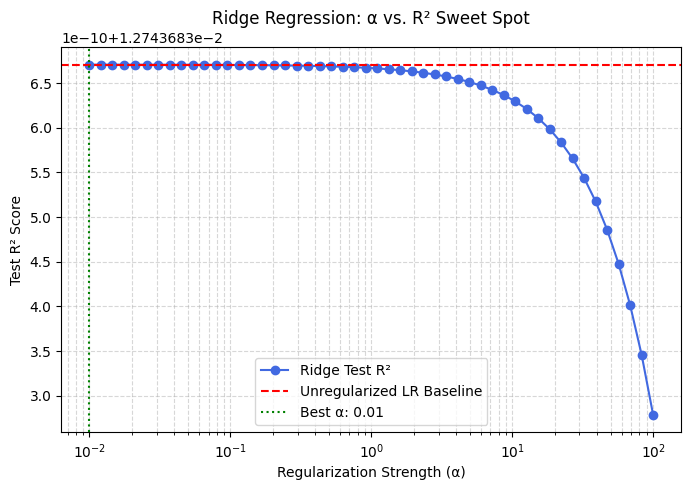

In [32]:
# 4. Plotting the Alpha Sweep
plt.figure(figsize=(8, 5))
plt.plot(alphas, ridge_test_scores, marker='o', color='royalblue', label='Ridge Test R²')
plt.axhline(lr_test_r2, color='red', linestyle='--', label='Unregularized LR Baseline')
plt.axvline(best_alpha, color='green', linestyle=':', label=f'Best α: {best_alpha:.2f}')

plt.xscale('log')
plt.xlabel('Regularization Strength (α)')
plt.ylabel('Test R² Score')
plt.title('Ridge Regression: α vs. R² Sweet Spot')
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.5)

In [33]:
# Save the deliverable
plt.savefig('ridge_alpha_sweep.png', dpi=300, bbox_inches='tight')
print("✅ Alpha-sweep plot successfully saved.")
plt.show()

✅ Alpha-sweep plot successfully saved.


<Figure size 640x480 with 0 Axes>

In [2]:
###Lasso, ElasticNet & Sparsity###

In [3]:
import pandas as pd
import numpy as np
from sklearn.linear_model import Lasso, ElasticNet
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [4]:
# 1. Train Lasso & Extract Zeroed Features
lasso = Lasso(alpha=1.0, random_state=42)
lasso.fit(X_train, y_train)
lasso_preds = lasso.predict(X_test)

zeroed_features = X_train.columns[lasso.coef_ == 0]
print(f"Lasso forced {len(zeroed_features)} features to exactly 0.")
print("Sample of dropped features:", list(zeroed_features[:5]))

NameError: name 'X_train' is not defined